# Машинное обучение, ФКН ВШЭ

# Практическое задание 9. Рекомендательные системы

## Общая информация

**Дата выдачи: 08.10.2026**

**Мягкий дедлайн: 25.10.2026 23:59 MSK**

**Жёсткий дедлайн: 08.11.2026 23:59 MSK**

## Оценивание и штрафы

Каждая из задач имеет определенную «стоимость» (указана в скобках около задачи). Максимально допустимая оценка за работу – **10** баллов за основную часть + **1.5** бонусных.

Сдавать задание после указанного срока сдачи нельзя. При выставлении неполного балла за задание в связи с наличием ошибок на усмотрение проверяющего предусмотрена возможность исправить работу на указанных в ответном письме условиях.

Задание выполняется самостоятельно. «Похожие» решения считаются плагиатом и все задействованные студенты (в том числе те, у кого списали) не могут получить за него больше 0 баллов (подробнее о плагиате см. на странице курса). Если вы нашли решение какого-то из заданий (или его часть) в открытом источнике, необходимо указать ссылку на этот источник в отдельном блоке в конце вашей работы (скорее всего вы будете не единственным, кто это нашел, поэтому чтобы исключить подозрение в плагиате, необходима ссылка на источник).

Неэффективная реализация кода может негативно отразиться на оценке.

## Формат сдачи
Задания сдаются через систему anytask. Посылка должна содержать:

* Ноутбук homework-practice-09-Username.ipynb

Username – ваша фамилия и имя на латинице именно в таком порядке

## О задании

В этой работе мы будем решать задачу рекомендации музыки (звуууук). То есть мы поставим целью получить модель, которая для каждого пользователя будет возвращать набор треков, наиболее похожих на те, что он уже слушал. В первой части мы разберемся с memory-based подходом и моделью со скрытыми переменными. Это не очень мощные методы, но зато они позволяют строить предсказания почти моментально. Затем, во второй части, мы обратим внимание на то, что датасет содержит огромное число треков и воспользуемся результатами уже построенных быстрых моделей для сокращения списка кандидатов до разумного количества. После этого проведем ранжирование среди кандидатов с помощью сильной, но чуть более медленной модели, и отберем самые лучшие варианты. Такой двухэтапный алгоритм построения рекомендаций изображен на картинке.


![](https://i.ibb.co/4RptSVjp/Screenshot-2026-03-23-at-00-29-18.png)

Приступим!

Все шаблоны ниже можно переписывать по своему усмотрению.

In [2]:
from sklearn.preprocessing import LabelEncoder

import pandas as pd
import numpy as np
from tqdm.notebook import tqdm
from typing import Callable, List

import matplotlib.pyplot as plt
import seaborn as sns
import scipy.sparse as scs

In [3]:
ratings = pd.read_csv('music_dataset.csv')
ratings.head()

,userId,trackId
0,0,14
1,0,95
2,0,219
3,0,220
4,0,404


In [4]:
tracks_info = pd.read_csv('tracks_info.csv')
tracks_info.head()

,id,name,artists
0,0,What There Is,['a-ha']
1,1,I'll Play The Blues For You,['Albert King']
2,2,Breaking Up Somebody's Home,['Albert King']
3,3,Imma Be,['Black Eyed Peas']
4,4,Boom Boom Pow,['Black Eyed Peas']


Для оценки качества рекомендаций мы будем использовать метрику $MAP@k$.

$$
MAP@k = \frac{1}{N} \sum_{u = 1}^N AP_u@k
$$
$$
AP_u@k = \frac{1}{\min(k, n_u)} \sum_{i=1}^k r_u(i) p_u@i
$$
$$p_u@k = \dfrac{1}{k}\sum_{j=1}^k r_u(j)$$


*   $N$ - количество пользователей.
*   $n_u$ - число релевантных треков пользователя $u$ на тестовом промежутке.
*   $r_u(i)$ - бинарная величина: относится ли трек на позиции $i$ к релевантным.

**Задание 1 (0.5 балл).** Реализуйте метрику $MAP@k$.

In [5]:
def mapk(relevant: List[List[int]], predicted: List[List[int]], k: int = 20):
    apks = []
    for rel, pred in zip(relevant, predicted):
        rel = set(rel)
        if not rel: # странная ситуация, там не описано что делать в этом случае. Я решил просто 0 возвращать.
            apks.append(0)
            continue
        now_rel, score = 0, 0
        for i, item in enumerate(pred[:k], start=1):
            if item in rel:
                now_rel += 1
                score += now_rel / i  # Прибавил текущее p_u@i
        apks.append(score / min(k, len(rel)))
    return np.mean(apks)

In [6]:
relevant = [
    [1, 7, 6, 2, 8],
    [1, 5, 4, 8],
    [8, 2, 5]
]

pred = [
    [8, 1, 5, 0, 7, 2, 9, 4],
    [0, 1, 8, 5, 3, 4, 7, 9],
    [9, 2, 0, 6, 8, 5, 3, 7]
]

assert round(mapk(relevant, pred, k=5), 4) == 0.4331

Отложим 50 последних строк каждого пользователя, остальные оставим для обучения. В данных нет времени прослушивания, поэтому это не временное разбиение.

Отложенные данные разделим по пользователям: на валидацию, обучение ранкера и финальный тест. В частях 1-2 параметры подбирайте по валидации.

In [7]:
def train_test_split(ratings):
    train_ratings, test_ratings = [], []
    num_test_samples = 50

    for userId, user_data in tqdm(ratings.groupby('userId')):
        train_ratings += [user_data[:-num_test_samples]]

    train_ratings = pd.concat(train_ratings).reset_index(drop=True)
    all_train_items = train_ratings['trackId'].unique()

    # getting train samples
    # we drop all tracks that are not presented it the training samples,
    # because we won't be able to learn representations for them
    for userId, user_data in tqdm(ratings.groupby('userId')):
        test_items = user_data[-num_test_samples:]
        test_items = test_items[np.isin(test_items['trackId'], all_train_items)]
        test_ratings += [test_items]

    test_ratings = pd.concat(test_ratings).reset_index(drop=True)

    return train_ratings, test_ratings

In [8]:
from sklearn.model_selection import train_test_split as split_users

train_ratings, holdout_ratings = train_test_split(ratings)

rank_test_users, valid_users = split_users(
    np.sort(holdout_ratings['userId'].unique()), test_size=0.2, random_state=42
)
rank_train_users, final_test_users = split_users(
    rank_test_users, test_size=0.4, random_state=42
)
rank_train_users = np.sort(rank_train_users)
valid_users = np.sort(valid_users)
final_test_users = np.sort(final_test_users)

rank_train_ratings = holdout_ratings[holdout_ratings['userId'].isin(rank_train_users)].copy()
test_ratings = holdout_ratings[holdout_ratings['userId'].isin(valid_users)].copy()
final_test_ratings = holdout_ratings[holdout_ratings['userId'].isin(final_test_users)].copy()

Python(34803) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


  0%|          | 0/241 [00:00<?, ?it/s]

  0%|          | 0/241 [00:00<?, ?it/s]

Почистим табличку с информацией о треках и закодируем id треков так, чтобы они соответствовали их порядковому номеру.

In [9]:
redundant_rows = np.where(~np.isin(tracks_info['id'], train_ratings['trackId'].unique()))[0]
tracks_info.drop(redundant_rows, inplace=True)
tracks_info = tracks_info.reset_index(drop=True)

In [10]:
def ids_encoder(ratings):
    users = sorted(ratings['userId'].unique())
    items = sorted(ratings['trackId'].unique())

    # create users and items encoders
    uencoder = LabelEncoder()
    iencoder = LabelEncoder()

    # fit users and items ids to the corresponding encoder
    uencoder.fit(users)
    iencoder.fit(items)

    return uencoder, iencoder

In [11]:
uencoder, iencoder = ids_encoder(train_ratings)
for frame in (train_ratings, test_ratings, rank_train_ratings, final_test_ratings):
    frame['trackId'] = iencoder.transform(frame['trackId'].tolist())
tracks_info['id'] = iencoder.transform(tracks_info['id'].tolist())

In [12]:
train_ratings.head()

,userId,trackId
0,0,14
1,0,95
2,0,219
3,0,220
4,0,404


In [13]:
test_ratings.head()

,userId,trackId
238,9,36055
239,9,36056
240,9,36058
241,9,36063
242,9,36139


Соберем все релевантные треки для каждого пользователя в список.

In [14]:
test_relevant = []
test_users = []
for user_id, user_data in test_ratings.groupby('userId'):
    test_relevant += [user_data['trackId'].tolist()]
    test_users.append(user_id)

final_test_relevant = (
    final_test_ratings.groupby('userId')['trackId'].agg(list)
    .reindex(final_test_users).tolist()
)

**Задание 2 (0.5 балла).** Реализуйте метод `get_test_recommendations` в классе `BaseModel`. Он принимает на вход параметр `k` и возвращает массив из `k` наиболее подходящих треков для каждого пользователя. Не забывайте удалять уже прослушанные треки из рекомендуемых. Аргумент `users` задаёт список пользователей (по умолчанию `test_users`); верните рекомендации в том же порядке.

In [15]:
class BaseModel:
    def __init__(self, ratings: pd.DataFrame):
        self.ratings = ratings
        self.n_users = len(np.unique(self.ratings['userId']))
        self.n_items = len(np.unique(self.ratings['trackId']))

        self.R = np.zeros((self.n_users, self.n_items))
        self.R[self.ratings['userId'], self.ratings['trackId']] = 1.

    def recommend(self, uid: int):
        """
        param uid: int - user's id
        return: [n_items] - vector of recommended items sorted by their scores in descending order
        """
        raise NotImplementedError

    def remove_train_items(self, preds: List[List[int]], k: int):
        """
        param preds: [n_users, n_items] - recommended items for each user
        param k: int
        return: np.array [n_users, k] - recommended items without training examples
        """
        new_preds = np.zeros((len(preds), k), dtype=int)
        for user_id, user_data in self.ratings.groupby('userId'):
            user_preds = preds[user_id]
            new_preds[user_id] = user_preds[~np.isin(user_preds, user_data['trackId'])][:k]

        return new_preds

    def get_test_recommendations(self, k: int, users: List[int] = None):
        if users is None:
            users = test_users

        test_preds = [self.recommend(user_id) for user_id in range(self.n_users)]

        test_preds = self.remove_train_items(test_preds, k) # хотим, чтобы рекомендовались ещё не прослушанные треки

        return test_preds[np.asarray(users)]

### Часть 1. Коллаборативная фильтрация (User2User)

Идея: чтобы выбрать треки, которые понравятся пользователю, можно набрать несколько похожих на него пользователей (соседей) и посмотреть, какие треки они слушают. После этого остается агрегировать треки этих пользователей и выбрать самые популярные. Соответственно, задача состоит из двух частей: выбора функции похожести двух пользователей и способа агрегации.

В качестве функции похожести мы будем использовать меру Жаккара:

$$ s(u, v) = \frac{|I_u \cap I_v|}{|I_u \cup I_v|} $$


Во всех формулах
* $I_u$ - множество треков, прослушанных пользователем $u$.
* $r_{ui}$ - прослушал ли пользователь $u$ трек $i$ (0 или 1).

Множество соседей определим как $$N(u) = \{ v \in U \setminus \{u\} \mid s(u, v) > \alpha\},$$ где $\alpha \, - $ гиперпараметр.



Для агрегации мы будем пользоваться следующей формулой.
$$
\hat{r}_{ui} = \frac{\sum_{v \in N(u)} s(u, v) r_{vi}}{\sum_{v \in N(u)} |s(u, v)|}
$$

**Задание 3 (0.5 балла).** Реализуйте функцию подсчета меры Жаккара.

Функция принимает матрицу оценок и вектор оценок пользователя $u$ и возвращает вектор со значениями похожести пользователя $u$ на всех пользователей. Старайтесь писать оптимизированный код, за неэффективную реализацию оценка может быть снижена.

In [16]:
def jaccard(ratings: np.array, user_vector: np.array) -> np.array:
    ratings = np.asarray(ratings)
    user_vector = np.asarray(user_vector)

    intersects = ratings @ user_vector # | I_u \cap I_v |
    ratings_sizes = ratings.sum(axis=1) # | I_v |
    user_size = user_vector.sum() # | I_u |
    unions = ratings_sizes + user_size - intersects # | I_u \cup I_v |

    result = np.zeros_like(intersects, dtype=float)
    notzero = unions != 0 # для остальных остаётся 0 как минимальное значение
    result[notzero] = intersects[notzero] / unions[notzero]

    return result

**Задание 4 (1 балл).** Реализуйте методы `similarity` и `recommend` класса `User2User`. `recommend` возвращает индексы треков, отсортированные в порядке убывания предсказанных оценок. Значение параметра `alpha` можно менять по своему усмотрению так, чтобы оно было разумным.

In [17]:
class User2User(BaseModel):
    def __init__(self, ratings):
        super().__init__(ratings)

        self.similarity_func = jaccard
        self.alpha = 0.02

    def similarity(self, user_vector: np.array):
        """
        user_vector: [n_items]
        """
        return self.similarity_func(self.R, user_vector)

    def recommend(self, uid: int):
        similarities = self.similarity(self.R[uid])
        similarities[uid] = 0 # мы сами себе не сосед

        neigh = np.where(similarities > self.alpha)[0]
        if not np.any(neigh):
            return np.argsort(self.R.sum(axis=0))[::-1] # если нет соседей, то мне кажется логичным просто рекомендовать самые популярные треки

        scores = self.R[neigh].T @ similarities[neigh]
        return np.argsort(scores)[::-1]


**Задание 5 (0.5 балл).** Постройте график зависимости значений $MAP@k$ от разных $k$ при рекомендации на основе меры Жаккара, сравните его с рекомендациями самых популярных треков и случайных. Какой из трех способов рекомендаций оказался лучшим?

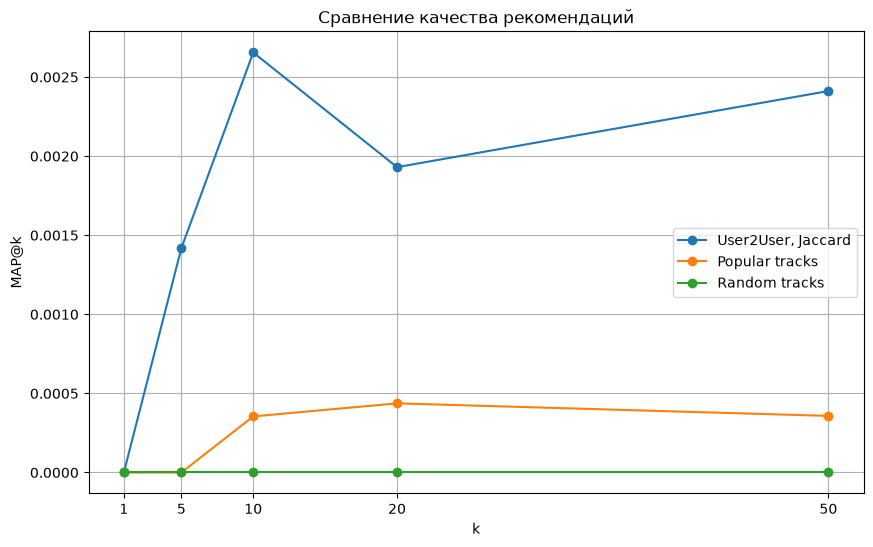

In [18]:
ks = [1, 5, 10, 20, 50]

# Рекомендации через User2User
model = User2User(train_ratings)
jaccard_scores = []

for k in ks:
    predictions = model.get_test_recommendations(k, users=test_users)
    score = mapk(test_relevant, predictions.tolist(), k=k)
    jaccard_scores.append(score)


# Вместе считаю рекомендации популярных и случайных треков
track_popularity = train_ratings["trackId"].value_counts().index.to_numpy() # При value_counts автоматически сортируется по убыванию
rng = np.random.default_rng(42)
all_tracks = np.arange(model.n_items)

popular_preds = []
random_preds = []

for user_id in test_users:
    listened = set(train_ratings.loc[train_ratings["userId"] == user_id, "trackId"].values)

    recommend_pop = []
    for track_id in track_popularity:
        if track_id not in listened:
            recommend_pop.append(track_id)

    recommend_rand = []
    shuffled_tracks = rng.permutation(all_tracks)
    for track_id in shuffled_tracks:
        if track_id not in listened:
            recommend_rand.append(track_id)
    
    popular_preds.append(recommend_pop)
    random_preds.append(recommend_rand)


popular_scores = []
random_scores = []
for k in ks:
    predicted_pop = [pred[:k] for pred in popular_preds]
    predicted_rand = [pred[:k] for pred in random_preds]
    popular_scores.append(mapk(test_relevant, predicted_pop, k=k))
    random_scores.append(mapk(test_relevant, predicted_rand, k=k))


# График
plt.figure(figsize=(10, 6))

plt.plot(ks, jaccard_scores, marker="o", label="User2User, Jaccard")
plt.plot(ks, popular_scores, marker="o", label="Popular tracks")
plt.plot(ks, random_scores, marker="o", label="Random tracks")

plt.xlabel("k")
plt.ylabel("MAP@k")
plt.title("Сравнение качества рекомендаций")
plt.xticks(ks)
plt.grid(True)
plt.legend()
plt.show()

Очевидно, наш умный метод с User2User и мерой Жаккара оказался лучшим. Также предсказуемо рекомндации популярных треков работают лучше чем рекомендации рандомных

**Бонус (0.5 балла).** Как вы могли заметить, матрица оценок получается очень разреженной, но мы работаем с ней как с обычной, это не дело. Перепишите код так, чтобы все методы могли работать с разреженными матрицами и сравните скорость работы такого подхода с оригинальным.

In [19]:
# your code here: ‿︵‿︵ヽ(°□° )ノ︵‿︵‿

Мы можем посмотреть глазами, насколько хорошо модель рекомендует треки. Для этого сравним уже прослушанные треки с рекомендованными и релевантными для случайного пользователя. Хорошо ли у вас получилось?

Хах, ну вроде неплохо подобрало

In [20]:
user_id = np.random.choice(test_users)

In [21]:
listened = train_ratings[train_ratings.userId == user_id].trackId[:15]

print('Already listened tracks:')

tracks_info.loc[listened][['name', 'artists']]

Already listened tracks:


,name,artists
9,Fix You,['Coldplay']
72,Naive,['The Kooks']
158,Don't Give Up,['Noisettes']
162,Stop And Stare,['OneRepublic']
165,Baby Fratelli,['The Fratellis']
167,America's Suitehearts,['Fall Out Boy']
228,Big Big World,['Emilia']
582,The Winner Takes It All,['ABBA']
716,Chelsea Dagger,['The Fratellis']
833,Grace Kelly,['MIKA']


In [22]:
preds = model.get_test_recommendations(15)

print('Predicted tracks:')

tracks_info.loc[preds[test_users.index(user_id)]][['name', 'artists']]

Predicted tracks:


,name,artists
45647,The Fear,['The Score']
33030,Revolution,['The Score']
35732,Disney Classics Medley,"['Alex G', 'Peter Hollens']"
36758,Miracle,['The Score']
18492,Merry Go Round of Life,['Yoshihiro Koseki']
41588,Thank God for Ireland,['Tyrone Wells']
42191,The Path of Silence,"['Gabriel Saban', 'Anne-Sophie Versnaeyen', 'P..."
21695,It's a Beautiful Day,['Tim McMorris']
43526,"Prokofiev: Romeo and Juliet, Op. 64 / Act 1 - ...","['Royal Philharmonic Orchestra', 'James Morgan..."
21942,The Song,"['Lisa Hannigan', ""Lucy O' Connell"", 'Bruno Co..."


In [23]:
test_tracks = test_ratings[test_ratings.userId == user_id].trackId[:15]

print('Validation tracks:')

tracks_info.loc[test_tracks][['name', 'artists']]

Validation tracks:


,name,artists
52381,Gurenge,['LiSA']
52511,Tom's Diner,"['AnnenMayKantereit', 'Giant Rooks']"
53034,Señorita,['Madilyn Bailey']
53087,WHISTLE,['BLACKPINK']
53092,BULLSHIT,['G-Dragon']
53522,California,['The Rose']
53599,Lover,['Taylor Swift']
53755,The Man,['Taylor Swift']
58022,Nicknames,"['Walk Off The Earth', 'gnash']"
58465,Maiochiruhanabira (Fallin' Flower),['Seventeen']


### Часть 2. Модель со скрытыми переменными: ALS

В этой части мы пощупаем метод рекомендаций со скрытыми переменными.
Идея: будем предсказывать оценки по формуле
$$
\hat{r}_{ui} = \langle p_u, q_i \rangle,
$$
$p_u \in \mathbb{R}^d$ и $q_i \in \mathbb{R}^d$ - латентные векторы пользователя $u$ и объекта $i$ соответственно.

Оптимизировать мы будем MSE между истинной оценкой пользователя и предсказанной с регуляризацией
$$
L = \sum_{(u, i) \in R} (\hat{r}_{ui} - r_{ui})^2 + \lambda \left(\sum_{u \in U} \|p_u\|^2 + \sum_{i \in I} \|q_i\|^2\right)
$$

__P. S.__ Заметьте, что описанная модель предназначена для работы только с __явной__ информацией. В нашем случае от модели будет требоваться всегда возвращать 1, так как мы считаем ошибку только по парам, о которых получили фидбек. Поэтому логично подумать, что постановка задачи не имеет смысла. Однако, на практике оказывается, что из-за случайности в инициализации матриц $P$ и $Q$, обученные векторы для всех треков и пользователей в конце обучения получаются разными. Поэтому модель все же не лишена смысла.

__P. P. S.__ Для более разумной работы с неявной информацией был предложен метод iALS, его описание можно найти в лекции. Ниже будет бонус на его реализацию.

**Задание 6 (0.5 балла).** На лекции рассматривались два подхода к оптимизации параметров. Можно это делать обычным стохастическим градинтным спуском, а можно по очереди обновлять матрицы $P, Q$, и тогда получится метод Alternating Least Squares (ALS). Выведите формулы обновления параметров для обоих методов.

**SGD:** \
Тут у нас сэмплится пара $(u, i)$, считаем производные:

$$
\frac{\partial L}{\partial p_u}=2(p_u^Tq_i-r_{ui})q_i+2\lambda p_u
$$

$$
\frac{\partial L}{\partial q_i}=2(p_u^Tq_i-r_{ui})p_u+2\lambda q_i
$$

Поэтому параметры обновляются так ($\eta$ - это learning rate):

$$
p_u  \:-\!\!=  \eta\left(2(p_u^Tq_i-r_{ui})q_i+2\lambda p_u\right)
$$

$$
q_i \:-\!\!= \eta\left(2(p_u^Tq_i-r_{ui})p_u+2\lambda q_i\right)
$$

Двойку в целом можно убрать и считать, что оно учитывается в $lr$

**ALS:** \
Фиксируем треки. Запишу в матричном виде, думаю так удобней будет. \
$L(p_u) = \|Q_u p_u - r_u\|^2 + \lambda \|p_u\|^2$. \
У $Q_u$ строки это $q_i^T$.

Обозначу за $a = Q_u p_u - r_u$. Тут $da = Q_u\, dp_u$.

$$d(a^T a + \lambda\ p_u^T p_u) = da^T a + a^T da + \lambda (dp_u^T p_u + p_u^T dp_u) = 2 (a^T da + \lambda p_u^T dp_u) =2((Q_u p_u - r_u)^T Q_u + \lambda p_u^T) dp_u $$

То есть градиент будет такой:

$$\nabla_{p_u} L = 2Q_u^T (Q_u p_u - r_u) + 2\lambda p_u$$
Приравниваем его к нулю получаем, что 
$$p_u=(Q_u^T Q_u + I)^{-1}Q_u^T r_u$$

При фиксировании пользователей решается аналогично. Формула обновления получается такая:
$$q_i = (P_i^T P_i + \lambda I)^{-1} P_i^T r_i ,$$
где строки $P_i$ — это $p_u^T$ и $r_i$ — вектор оценок товара $i$.



**Задание 7 (1.5 балла).** Реализуйте методы оптимизации параметров для обоих алгоритмов.

In [24]:
class LatentFactorModel(BaseModel):
    def __init__(self, ratings, dim=128, mode='sgd', lr=0.0003, lamb=0.01, alpha=60.0):
        super().__init__(ratings)
        self.dim = dim

        assert mode in ['sgd', 'als', 'ials']
        self.mode = mode

        self.P = np.random.normal(size=(self.n_users, dim))
        self.Q = np.random.normal(size=(self.n_items, dim))

        self.lr = lr
        self.lamb = lamb
        self.alpha = alpha

    def fit(self, num_iters=5):
        user_ids = self.ratings['userId'].to_numpy(dtype=int)
        item_ids = self.ratings['trackId'].to_numpy(dtype=int)
        eye = np.eye(self.dim)
        user_items = self.ratings.groupby('userId')['trackId'].agg(list) # для ALS списки от треков по пользователям и наоборот
        item_users = self.ratings.groupby('trackId')['userId'].agg(list)

        progress = tqdm(
            range(num_iters),
            desc=f'{self.mode.upper()} (dim={self.dim}, epochs={num_iters})',
            leave=False,
        )
        for epoch in progress:
            if self.mode == 'sgd':
                order = np.random.permutation(len(self.ratings))
                for ind in order:
                    user_id = user_ids[ind]
                    item_id = item_ids[ind]

                    p_u = self.P[user_id].copy()
                    q_i = self.Q[item_id].copy()
                    err = p_u @ q_i - 1.0

                    self.P[user_id] -= self.lr * (err * q_i + self.lamb * p_u)
                    self.Q[item_id] -= self.lr * (err * p_u + self.lamb * q_i)

            elif self.mode == 'als':
                for user_id in range(self.n_users):
                    Q_u = self.Q[user_items[user_id]]

                    A = Q_u.T @ Q_u + self.lamb * eye
                    b = Q_u.sum(axis=0) # Считаем, что r_u из единичек
                    self.P[user_id] = np.linalg.solve(A, b)

                for item_id in range(self.n_items):
                    P_i = self.P[item_users[item_id]]

                    A = P_i.T @ P_i + self.lamb * eye
                    b = P_i.sum(axis=0) # Считаем, что r_i из единичек
                    self.Q[item_id] = np.linalg.solve(A, b)

            elif self.mode == 'ials':
                w = 1.0 + self.alpha
                qt_q = self.Q.T @ self.Q
                for user_id in range(self.n_users):
                    Q_u = self.Q[user_items[user_id]]
                    A = qt_q + self.alpha * (Q_u.T @ Q_u) + self.lamb * eye
                    b = w * Q_u.sum(axis=0)
                    self.P[user_id] = np.linalg.solve(A, b)

                pt_p = self.P.T @ self.P
                for item_id in range(self.n_items):
                    P_i = self.P[item_users[item_id]]
                    A = pt_p + self.alpha * (P_i.T @ P_i) + self.lamb * eye
                    b = w * P_i.sum(axis=0)
                    self.Q[item_id] = np.linalg.solve(A, b)

    def recommend(self, uid):
        pred_rating = self.P[uid] @ self.Q.T

        return np.argsort(pred_rating)[::-1]

**Задание 8 (1 балл).** Для обоих алгоритмов подберите оптимальные значения размерности скрытого пространства $d$ и размера предсказания $k$. Как изменяется качество предсказаний с числом итераций обучения? Постройте соответствующие графики, сравните со случайным подходом и User2User, сделайте выводы. Какой алгоритм вам кажется более подходящим для данной задачи и почему?

__P. S.__ Хотя бы один из методов обучения должен приводить к лучшим результатам в сравнении с User2User подходом.

__P. P. S.__ Методу SGD свойственно переобучаться, поэтому при подборе параметров полезно смотреть на значения ошибки и оптимизируемой метрики на тренировочном датасете. Вы также можете менять начальную инициализацию и прочие параметры, за исключением архитектуры, на ваш вкус.

SGD (dim=32, epochs=5):   0%|          | 0/5 [00:00<?, ?it/s]

SGD (dim=32, epochs=5):   0%|          | 0/5 [00:00<?, ?it/s]

SGD (dim=32, epochs=5):   0%|          | 0/5 [00:00<?, ?it/s]

SGD (dim=8, epochs=5):   0%|          | 0/5 [00:00<?, ?it/s]

SGD (dim=8, epochs=5):   0%|          | 0/5 [00:00<?, ?it/s]

SGD (dim=8, epochs=5):   0%|          | 0/5 [00:00<?, ?it/s]

... (30 outputs left out)

ALS (dim=60, epochs=5):   0%|          | 0/5 [00:00<?, ?it/s]

ALS (dim=60, epochs=5):   0%|          | 0/5 [00:00<?, ?it/s]

ALS (dim=60, epochs=5):   0%|          | 0/5 [00:00<?, ?it/s]

Лучшие параметры для каждой dim:

SGD:
dim=8: lambda=0.001, MAP@20=0.000213
dim=16: lambda=0.001, MAP@20=0.000000
dim=28: lambda=0.001, MAP@20=0.000000
dim=32: lambda=0.001, MAP@20=0.000532
dim=38: lambda=0.001, MAP@20=0.000000
dim=60: lambda=0.001, MAP@20=0.000066

ALS:
dim=8: lambda=0.1, MAP@20=0.001064
dim=16: lambda=0.001, MAP@20=0.001140
dim=28: lambda=0.001, MAP@20=0.001299
dim=32: lambda=0.001, MAP@20=0.001613
dim=38: lambda=0.1, MAP@20=0.000284
dim=60: lambda=0.001, MAP@20=0.000303


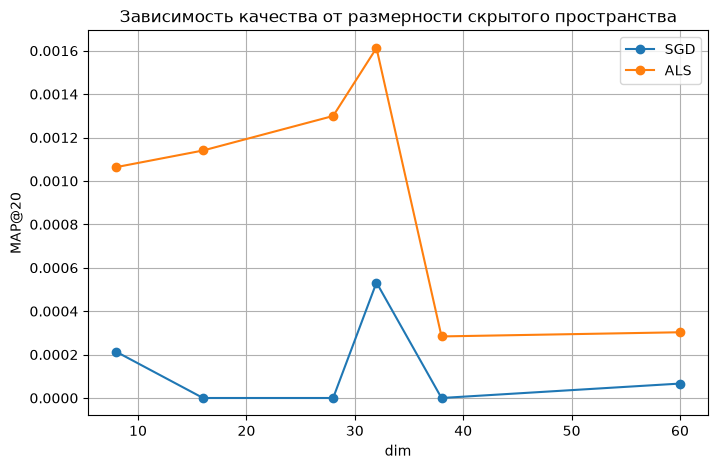

SGD (dim=32, epochs=1):   0%|          | 0/1 [00:00<?, ?it/s]

SGD (dim=32, epochs=2):   0%|          | 0/2 [00:00<?, ?it/s]

SGD (dim=32, epochs=5):   0%|          | 0/5 [00:00<?, ?it/s]

SGD (dim=32, epochs=10):   0%|          | 0/10 [00:00<?, ?it/s]

ALS (dim=32, epochs=1):   0%|          | 0/1 [00:00<?, ?it/s]

ALS (dim=32, epochs=2):   0%|          | 0/2 [00:00<?, ?it/s]

ALS (dim=32, epochs=5):   0%|          | 0/5 [00:00<?, ?it/s]

ALS (dim=32, epochs=10):   0%|          | 0/10 [00:00<?, ?it/s]

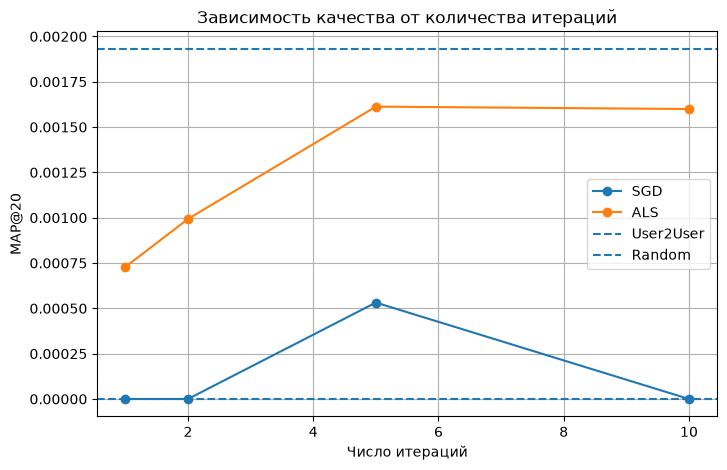

SGD (dim=32, epochs=5):   0%|          | 0/5 [00:00<?, ?it/s]

ALS (dim=32, epochs=5):   0%|          | 0/5 [00:00<?, ?it/s]

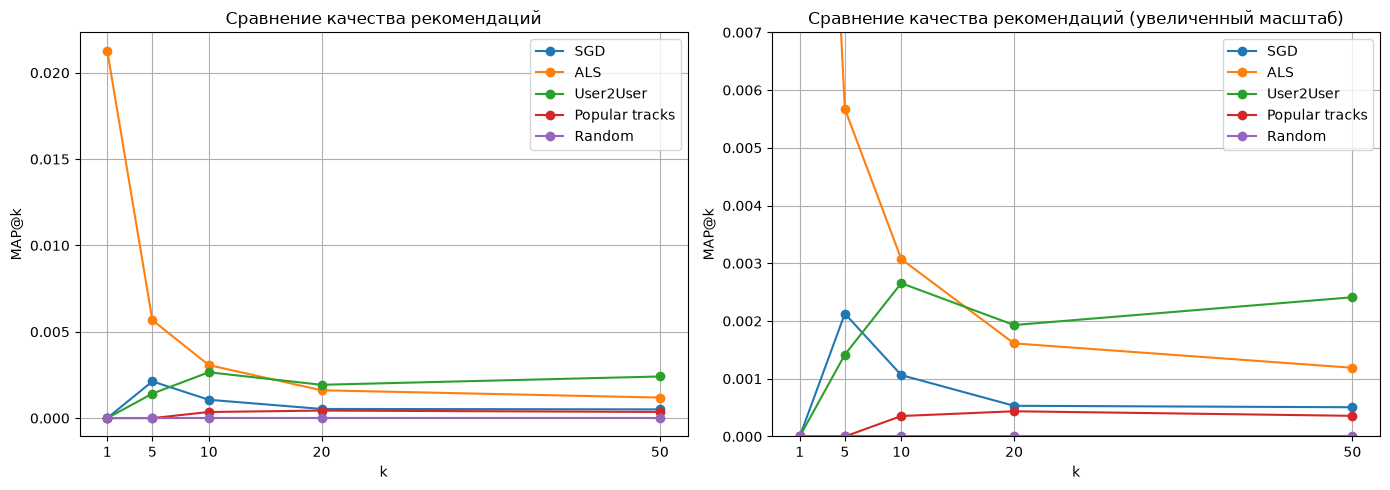

Лучший lr для SGD: 0.003
Лучшие lambda: {'sgd': 0.001, 'als': 0.001}
Лучшие dim по MAP@20: {'sgd': 32, 'als': 32}
Лучшее число итераций по MAP@20: {'sgd': 5, 'als': 5}
Лучший результат SGD: (5, np.float64(0.002127659574468085))
Лучший результат ALS: (1, np.float64(0.02127659574468085))
User2User MAP@20: 0.0019305133400878082


In [25]:
dims = [8, 16, 28, 32, 38, 60]
ks = [1, 5, 10, 20, 50]
num_iters = [1, 2, 5, 10]
lrs = [0.0003, 0.001, 0.003]
lambdas = [0.001, 0.01, 0.1]

def run_lfm(dim, mode, epochs=5, ks=ks, lr=0.0003, lamb=0.01):
    np.random.seed(42)
    lfm = LatentFactorModel(train_ratings, dim=dim, mode=mode, lr=lr, lamb=lamb)
    lfm.fit(num_iters=epochs)
    preds = lfm.get_test_recommendations(max(ks))
    scores = {
        k: mapk(test_relevant, preds.tolist(), k=k)
        for k in ks
    }
    return lfm, scores


# Подбираю lr для SGD. Другие параметры: dim=32, k=20, lambda и количество эпох оставил по умолчанию
lr_scores = {}
for lr in lrs:
    _, scores = run_lfm(32, 'sgd', lr=lr)
    lr_scores[lr] = scores[20]
best_lr = max(lr_scores, key=lambda x: lr_scores[x])

best_lrs = {'sgd': best_lr, 'als': 0}
 # Написал так (а не просто везде best_lr), потому что так прозрачнее что мы используем разные lr для разных алгоритмов
 # и если мы захотим добавить ещё алгоритмов, то удобно будет в этот словарь добавить

# Совместно подбираю dim и lambda. Вроде оони сильно взаимосвязаны (dim даёт запомнить больше информации, а lambda не даёт переобучиться)
# Снизу проверю, что реально для разных dim подходят разные lambda.
dim_scores = {
    'sgd': {},
    'als': {},
}

best_params_by_dim = {
    'sgd': {},
    'als': {},
}

for mode in ['sgd', 'als']:
    for dim in dims:
        best_score = -np.inf
        best_lamb_for_dim = None

        for lamb in lambdas:
            _, scores = run_lfm( dim=dim, mode=mode, epochs=5, lr=best_lrs[mode], lamb=lamb)
            score = scores[20]

            if score > best_score:
                best_score = score
                best_lamb_for_dim = lamb

        dim_scores[mode][dim] = best_score
        best_params_by_dim[mode][dim] = {
            'lamb': best_lamb_for_dim,
            'score': best_score,
        }

best_dims = {
    mode: max(scores, key=lambda x: scores[x])
    for mode, scores in dim_scores.items()
}

best_lambdas = {
    mode: best_params_by_dim[mode][best_dims[mode]]['lamb']
    for mode in ('sgd', 'als')
}

# Проверяю гипотезу, что для разных dim подходят разные lambda на всякий случай
print('Лучшие параметры для каждой dim:')
for mode in ('sgd', 'als'):
    print(f'\n{mode.upper()}:')
    for dim, params in best_params_by_dim[mode].items():
        print(
            f'dim={dim}: '
            f'lambda={params["lamb"]}, '
            f'MAP@20={params["score"]:.6f}'
        )

plt.figure(figsize=(8, 5))
for mode, scores in dim_scores.items():
    plt.plot(list(scores), list(scores.values()), marker='o', label=mode.upper())
plt.xlabel('dim')
plt.ylabel('MAP@20')
plt.title('Зависимость качества от размерности скрытого пространства')
plt.grid(True)
plt.legend()
plt.show()


# Для графика зависимости качества от числа итераций
iteration_scores = {'sgd': [], 'als': []}
for mode in iteration_scores:
    for n_iters in num_iters:
        _, scores = run_lfm(
            best_dims[mode],
            mode,
            epochs=n_iters,
            lr=best_lrs[mode],
            lamb=best_lambdas[mode],
        )
        iteration_scores[mode].append(scores[20])

best_epochs = {
    mode: num_iters[int(np.argmax(scores))]
    for mode, scores in iteration_scores.items()
}

plt.figure(figsize=(8, 5))
for mode, scores in iteration_scores.items():
    plt.plot(num_iters, scores, marker='o', label=mode.upper())
plt.axhline(jaccard_scores[ks.index(20)], linestyle='--', label='User2User')
plt.axhline(random_scores[ks.index(20)], linestyle='--', label='Random')
plt.xlabel('Число итераций')
plt.ylabel('MAP@20')
plt.title('Зависимость качества от количества итераций')
plt.grid(True)
plt.legend()
plt.show()


# Главный график: зависимость MAP@k от k при лучших подобранных других параметрах
best_models = {}
lfm_scores = {}
for mode in ['sgd', 'als']:
    best_models[mode], lfm_scores[mode] = run_lfm(
        best_dims[mode],
        mode,
        epochs=best_epochs[mode],
        lr=best_lrs[mode],
        lamb=best_lambdas[mode],
    )

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
curves = {
    'SGD': [lfm_scores['sgd'][k] for k in ks],
    'ALS': [lfm_scores['als'][k] for k in ks],
    'User2User': jaccard_scores,
    'Popular tracks': popular_scores,
    'Random': random_scores,
}

def draw_my_plot(ax, title, ylim=None):
    for label, values in curves.items():
        ax.plot(
            ks,
            values,
            marker='o',
            label=label,
        )
    if ylim is not None:
        ax.set_ylim(*ylim)
    ax.set_xlabel('k')
    ax.set_ylabel('MAP@k')
    ax.set_title(title)
    ax.set_xticks(ks)
    ax.grid(True)
    ax.legend()

draw_my_plot(axes[0], 'Сравнение качества рекомендаций')
draw_my_plot(axes[1], 'Сравнение качества рекомендаций (увеличенный масштаб)', ylim=(0, 0.007))
plt.tight_layout()
plt.show()

print('Лучший lr для SGD:', best_lr)
print('Лучшие lambda:', best_lambdas)
print('Лучшие dim по MAP@20:', best_dims)
print('Лучшее число итераций по MAP@20:', best_epochs)
print('Лучший результат SGD:', max(lfm_scores['sgd'].items(), key=lambda x: x[1]))
print('Лучший результат ALS:', max(lfm_scores['als'].items(), key=lambda x: x[1]))
print('User2User MAP@20:', jaccard_scores[ks.index(20)])


#### По поводу dim
dim оптимальное для обоих алгоритмов оказалось 32. Вопреки моим предположениям lambda в зависимости от dim почти не менялось. Я думал, что чем больше dim, тем больше понадобится lambda. Возможно не тот диапазон для lambda выбрал. Впрочем, и ладно. Заново такую долгую ячейку я запускать не буду, и так уже назапускался.

#### По поводу числа итераций
На графике видно, что у ALS первые 5 итераций качество хорошо растёт, но дальше выходит на плато. Значит для него обучать больше 5-ти итераций особо не имеет смысла тут, достаточно быстро сходится.
У SGD же немного другая ситуация: тут есть сильная зависимость от числа итераций. На 5-той итерации качество хорошее, но к 10-ой оно снова падает к нулю. Я думаю это связано с переобучением. Тут просто нужно когда его обучаешь делать раннюю остановку. Когда останавливаться можно понять по качеству на валидационной выборке, где оно максимальное, там и останавливаемся.

#### Выбор лучшего алгоритма
Тут зависит от количества рекомендаций, которое нам нужно. Если $k=1$, то конечно ALS. Он показывает очень хорошее качество при таком $k$, но при этом при увеличении $k$, качество быстро падает (выдаёт значит треки дальше не очень релевантные).
В общем, если до 15 треков рекомендовать надо, то выбираем ALS, иначе User2User, так как User2User достаточно стабильно себя ведёт при увеличении $k$ (не падает, а даже чуть подрастает)

___

Если у вас получилось достаточно хорошее качество, то при оптимизации параметров марицы $Q$ похожим трекам стали соответствовать похожие векторы. Поэтому мы можем для любого трека найти наиболее близкие к нему в латентном пространстве и проверить степерь обученности модели вручную.

In [26]:
model = best_models['als']

example_trackId = tracks_info[tracks_info.name == 'Выхода нет'].iloc[0].id

preds = model.Q @ model.Q[example_trackId]
preds = preds / np.sqrt((model.Q**2).sum(axis=1) + 1e-8)

track_idxs = preds.argsort()[::-1][:20]

In [27]:
similar_tracks = tracks_info.loc[track_idxs][['name', 'artists']]
similar_tracks['similarity'] = preds[track_idxs] / np.linalg.norm(model.Q[example_trackId])
similar_tracks

,name,artists,similarity
5512,Выхода нет,['Сплин'],1.000000
16192,Однажды мир прогнётся под нас,['Машина времени'],0.732559
16803,Tous Les Mêmes,['Stromae'],0.719854
23093,Sunny,['Boney M.'],0.715777
15123,Susanna,['Celentano'],0.709166
5724,Rise Up,['Yves Larock'],0.681505
2060,Хочу перемен,['КИНО'],0.679168
35332,Area,['MagnusTheMagnus'],0.668942
5528,Red Stars,['The Birthday Massacre'],0.662487
3191,Riders on the Storm,['The Doors'],0.657662


**Бонус (1 балл).**

Постройте модель iALS и сравните ее качество с обучением ALS и SGD.

IALS (dim=32, epochs=5):   0%|          | 0/5 [00:00<?, ?it/s]

IALS (dim=32, epochs=5):   0%|          | 0/5 [00:00<?, ?it/s]

IALS (dim=32, epochs=5):   0%|          | 0/5 [00:00<?, ?it/s]

IALS (dim=32, epochs=5):   0%|          | 0/5 [00:00<?, ?it/s]

IALS (dim=32, epochs=5):   0%|          | 0/5 [00:00<?, ?it/s]

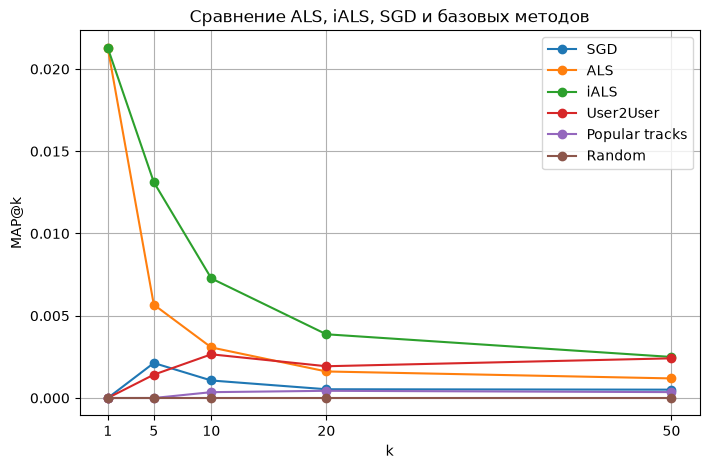

Результаты подбора alpha: {30.0: np.float64(0.0022633059363182544), 40.0: np.float64(0.003809312732185073), 50.0: np.float64(0.003445983685345388), 70.0: np.float64(0.0038733075435203094), 80.0: np.float64(0.003705673758865249)}
Лучший alpha: 70.0
iALS MAP@20: 0.0038733075435203094


In [28]:
# Формулы для iALS выводятся похоже на то как в ALS, просто немного более громоздко

alpha_grid = [30.0, 40.0, 50.0, 70.0, 80.0]
ials_alpha_scores = {}
ials_models = {}

for alpha in alpha_grid:
    np.random.seed(42)
    ials_model = LatentFactorModel(
        train_ratings,
        dim=best_dims['als'],
        mode='ials',
        lamb=best_lambdas['als'],
        alpha=alpha,
    )
    ials_model.fit(num_iters=best_epochs['als'])
    predictions = ials_model.get_test_recommendations(max(ks))
    ials_alpha_scores[alpha] = mapk(test_relevant, predictions.tolist(), k=20)
    ials_models[alpha] = ials_model


best_alpha = max(ials_alpha_scores, key=lambda x: ials_alpha_scores[x])
ials_model = ials_models[best_alpha]
ials_preds = ials_model.get_test_recommendations(max(ks))
ials_scores = {
    k: mapk(test_relevant, ials_preds.tolist(), k=k)
    for k in ks
}

plt.figure(figsize=(8, 5))
for mode, scores in lfm_scores.items():
    plt.plot(ks, [scores[k] for k in ks], marker='o', label=mode.upper())
plt.plot(ks, [ials_scores[k] for k in ks], marker='o', label='iALS')
plt.plot(ks, jaccard_scores, marker='o', label='User2User')
plt.plot(ks, popular_scores, marker='o', label='Popular tracks')
plt.plot(ks, random_scores, marker='o', label='Random')
plt.xlabel('k')
plt.ylabel('MAP@k')
plt.title('Сравнение ALS, iALS, SGD и базовых методов')
plt.xticks(ks)
plt.grid(True)
plt.legend()
plt.show()

print('Результаты подбора alpha:', ials_alpha_scores)
print('Лучший alpha:', best_alpha)
print('iALS MAP@20:', ials_scores[20])

Вау! Ну Он работает явно везде лучше чем ALS и SGD. При этом выше User2User он наверняка только при $k\leq50$ (тут они пересекаются, и дальше наверное расходятся в разные стороны: iALS дальше вниз, а User2User также примерно, или чуть растёт).

### Часть 3. Второй уровень рекомендаций.

Выше мы построили простейшие модели, которые показывают не слишком высокое качество, но зато работают очень быстро. Воспользуемся ими для того, чтобы отобрать некоторое количество наиболее перспективных треков, которые мы сможем отранжировать уже более сложной моделью (в нашем случае это будет [CatBoost](https://catboost.ai/en/docs/concepts/python-reference_catboost)).

**Задание 9 (0.5 балла).**

Для каждого пользователя возьмите топ-100 рекомендованных треков от модели LFM (ALS или SGD на ваш выбор) и топ-100 от модели User2User. Это будут наши кандидаты, которые мы затем будем ранжировать бустингом.

Объедините кандидатов без дублей и уже прослушанных треков. Используйте модели, обученные на `train_ratings`, с уже выбранными параметрами.

In [32]:
# Беру iALS, раз я его написал и он лучше чем ALS и SGD
lfm_model = ials_model
user2user_model = User2User(train_ratings)

# Обернул в функцию, так как дальше надо будет и для valid и test тоже получить кандидатов
def get_candidates(users, k=100):
    lfm_preds = lfm_model.get_test_recommendations(k, users=users)
    u2u_preds = user2user_model.get_test_recommendations(k, users=users)
    res = {}
    for i, user_id in enumerate(users):
        listened = set(train_ratings.loc[train_ratings["userId"] == user_id, "trackId"].values)
        res[user_id] = sorted((set(lfm_preds[i]) | set(u2u_preds[i])) - listened)
    return res

candidates = get_candidates(rank_train_users)

print('Число пользователей:', len(candidates))
print('Среднее число кандидатов:', np.mean([len(items) for items in candidates.values()]))

Число пользователей: 112
Среднее число кандидатов: 181.58928571428572


**Задание 10 (1.5 балла).**

Подготовьте датасет для обучения модели ранжирования. Он должен состоять из пар: объект, целевая переменная. Объект - это пара (user, item) и всякие дополнительные признаки на их основе. Предлагается создать набор следующих признаков, однако вы можете добавлять свои по желанию, если они вам кажутся разумными (признаки считаем на основе `train_ratings`):
 1) id пользователя
 1) id трека
 1) косинусное расстояние между эмбеддингами LFM соответствующих пользователя и трека
 1) среднее значение меры Жаккара между этим пользователем и остальными из User2User модели
 1) доля пользователей, слушавших этот трек (взять из обучающей выборки в Части 1)
 1) количество прослушанных пользователем треков (взять из обучающей выборки в Части 1)

В качестве целевой переменной возьмем бинарную метку "попал ли трек в отложенные взаимодействия пользователя".

__P.S.__ Датасет для обучения модели ранжирования строится на юзерах, которых мы в начале выделили для обучения ранкера. 

In [36]:
item_listen_share = user2user_model.R.mean(axis=0) # пункт 5
user_n_listened = user2user_model.R.sum(axis=1) # пункт 6

jaccard_all = np.array([
    user2user_model.similarity(user2user_model.R[user_id])
    for user_id in range(user2user_model.n_users)
])
np.fill_diagonal(jaccard_all, 0) # Я думаю так будет правильней. В User2User в recommend я занулял меру Жаккара для самого себя
user_mean_jaccard = jaccard_all.sum(axis=1) / (len(jaccard_all) - 1) # пункт 4

P_norm = lfm_model.P / np.maximum(np.linalg.norm(lfm_model.P, axis=1, keepdims=True), 1e-12) # максимум делаю как защиту от деления на 0
Q_norm = lfm_model.Q / np.maximum(np.linalg.norm(lfm_model.Q, axis=1, keepdims=True), 1e-12)


def build_dataset(candidates, holdout):
    pairs = pd.Series(candidates).explode().reset_index()
    pairs.columns = ['userId', 'trackId']
    pairs = pairs.astype(int)

    # Добавляю таргет
    positive_pairs = set(zip(holdout['userId'], holdout['trackId']))
    pairs['target'] = [
        int((user_id, track_id) in positive_pairs) # 1, если есть в отложенной выборке, иначе 0 будет
        for user_id, track_id in zip(pairs['userId'], pairs['trackId'])
    ]

    # Добавляю признаки
    u = pairs['userId'].to_numpy()
    i = pairs['trackId'].to_numpy()
    pairs['lfm_cos_dist'] = 1 - (P_norm[u] * Q_norm[i]).sum(axis=1)
    pairs['user_mean_jaccard'] = user_mean_jaccard[u]
    pairs['item_listen_share'] = item_listen_share[i]
    pairs['user_n_listened'] = user_n_listened[u]
    
    return pairs.drop(columns='target'), pairs['target'].to_numpy(), pairs['userId'].to_numpy()


# для train кандидатов беру из задания 9, а для val и test генерирую функцией
X_train, y_train, train_group_id = build_dataset(candidates, rank_train_ratings)
X_valid, y_valid, valid_group_id = build_dataset(get_candidates(valid_users), test_ratings)
X_test, y_test, test_group_id = build_dataset(get_candidates(final_test_users), final_test_ratings)

X_train.sample(5)

,userId,trackId,lfm_cos_dist,user_mean_jaccard,item_listen_share,user_n_listened
3833,49,56367,0.596598,0.001500,0.008299,146.0
17919,206,3191,0.623301,0.008956,0.082988,225.0
1907,22,7780,0.796408,0.006581,0.149378,360.0
10246,120,3574,0.851986,0.013599,0.136929,400.0
7147,79,2814,0.943513,0.002747,0.240664,113.0


Как уже было сказано, для построения ранжирующей модели мы будем пользоваться библиотекой [CatBoost](https://www.youtube.com/watch?v=X1-MXdyThJ0).

Для преобразования датасета в удобный вид полезно использовать метод [`Pool`](https://catboost.ai/en/docs/concepts/python-reference_pool).

In [38]:
import catboost

def sort_by_group(X, y, group_id):
    group_id = np.asarray(group_id)
    order = np.argsort(group_id, kind='stable')
    if hasattr(X, 'iloc'):
        X = X.iloc[order]
    elif scs.issparse(X):
        X = X.tocsr()[order]
    else:
        X = np.asarray(X)[order]
    return X, np.asarray(y)[order], group_id[order], order

# group_id == user_id here; строки каждой группы должны идти подряд
X_train, y_train, train_group_id, train_order = sort_by_group(X_train, y_train, train_group_id)
X_valid, y_valid, valid_group_id, valid_order = sort_by_group(X_valid, y_valid, valid_group_id)  
X_test, y_test, test_group_id, test_order = sort_by_group(X_test, y_test, test_group_id) 

train_pool = catboost.Pool(X_train, y_train, group_id=train_group_id)
valid_pool = catboost.Pool(X_valid, y_valid, group_id=valid_group_id)
test_pool = catboost.Pool(X_test, y_test, group_id=test_group_id)

__P.S.__ Обучающая выборка здесь для ранкера, а тестовая - для финальной оценки. Валидационная та же, на которой подбирали параметры предыдущих моделей. Заново делить данные не нужно

**Задание 11 (1 балл)**

Обучите `CatBoostClassifier`. С его помощью сделайте предсказания для тестовой выборки и посчитайте MAP@20. Сравните с рекомендациями моделей User2User и LFM. Учтите, что для честного сравнения необходимо пересчитать предсказания моделей на нашей новой тестовой выборке. Получилось ли улучшить результаты?

В заданиях 11–12 сначала настройте обе модели на валидации, затем сравните их на тесте. MAP@20 считайте для всех: не убирайте треки, не попавшие в кандидаты, а пользователям без рекомендаций оставьте пустой список.

In [56]:
def recommendations_from_scores(X, scores, users):
    X = X.copy()
    X['score'] = scores

    return [
        X[X['userId'] == user_id]
        .sort_values('score', ascending=False)['trackId'] # Сортирую треки по скору
        .tolist()
        for user_id in users
    ]

def tracks_by_users(ratings, users):
    # Возвращает список треков по пользователям
    tracks = ratings.groupby('userId')['trackId'].agg(list).to_dict()
    return [tracks.get(user_id, []) for user_id in users]


# Тут создаю новые, так как по идее тут не нужны group_id, и лучше разделить эти сущности. Те будут для 12 задания
classifier_train_pool = catboost.Pool(X_train, y_train) 
classifier_valid_pool = catboost.Pool(X_valid, y_valid)
classifier_test_pool = catboost.Pool(X_test, y_test)

validation_relevant = tracks_by_users(test_ratings, valid_users)
best_model = None
best_val_map = -1
best_parameters = None

for lr in [0.03, 0.07, 0.1]:
    for iterations in [100, 140, 180, 250]:
        for depth in [4, 6]:
            candidate_model = catboost.CatBoostClassifier(
                iterations=iterations,
                learning_rate=lr,
                depth=depth,
                loss_function='Logloss',
                random_seed=42,
                verbose=False,
            )
            candidate_model.fit(
                classifier_train_pool,
                eval_set=classifier_valid_pool,
                use_best_model=True,
                verbose=False,
            )
            scores = candidate_model.predict_proba(classifier_valid_pool)[:, 1]
            predictions = recommendations_from_scores(X_valid, scores, valid_users)
            now_map = mapk(validation_relevant, predictions, k=20)
            if now_map > best_val_map:
                best_model = candidate_model
                best_val_map = now_map
                best_parameters = (lr, iterations, depth)


classifier = best_model
classifier_test_scores = classifier.predict_proba(classifier_test_pool)[:, 1]
classifier_predictions = recommendations_from_scores(X_test, classifier_test_scores, final_test_users)
test_relevant = tracks_by_users(final_test_ratings, final_test_users)
classifier_map20 = mapk(test_relevant, classifier_predictions, k=20)


lfm_predictions = lfm_model.get_test_recommendations(100, users=final_test_users).tolist()
u2u_predictions = user2user_model.get_test_recommendations(100, users=final_test_users).tolist()
lfm_map20 = mapk(test_relevant, lfm_predictions, k=20)
u2u_map20 = mapk(test_relevant, u2u_predictions, k=20)


print('Лучшие параметры:', best_parameters)
print(f'Validation MAP@20: {best_val_map:.6f}')
print(f'CatBoostClassifier MAP@20: {classifier_map20:.6f}')
print(f'LFM MAP@20: {lfm_map20:.6f}')
print(f'User2User MAP@20: {u2u_map20:.6f}')

Лучшие параметры: (0.1, 100, 4)
Validation MAP@20: 0.021377
CatBoostClassifier MAP@20: 0.013768
LFM MAP@20: 0.000818
User2User MAP@20: 0.000240


Да, результаты сильно подросли. Примерно на два порядка больше стало. Класс

**Задание 12 (1 балл)**

Обучите `CatBoostRanker`, выбрав подходящую функцию ранжирования из тех, которые были рассмотрены на лекции. Проделайте все те же действия, что и с `CatBoostClassifier` и сравните результаты.

In [60]:
best_ranker = None
best_ranker_map = -1
best_ranker_parameters = None

for lr in [0.03, 0.07, 0.1]:
    for iterations in [100, 200, 400]:
        for depth in [4, 6]:
            candidate_ranker = catboost.CatBoostRanker(
                iterations=iterations,
                learning_rate=lr,
                depth=depth,
                eval_metric='NDCG:top=20',
                random_seed=42,
                verbose=False,
            )
            candidate_ranker.fit(
                train_pool,
                eval_set=valid_pool,
                use_best_model=True,
                verbose=False,
            )
            scores = candidate_ranker.predict(valid_pool)
            predictions = recommendations_from_scores(X_valid, scores, valid_users)
            now_map = mapk(validation_relevant, predictions, k=20)
            if now_map > best_ranker_map:
                best_ranker = candidate_ranker
                best_ranker_map = now_map
                best_ranker_parameters = (lr, iterations, depth)

ranker = best_ranker
ranker_test_scores = ranker.predict(test_pool)
ranker_predictions = recommendations_from_scores(
    X_test, ranker_test_scores, final_test_users
)
ranker_map20 = mapk(test_relevant, ranker_predictions, k=20)

print('Лучшие параметры CatBoostRanker:', best_ranker_parameters)
print(f'Validation MAP@20: {best_ranker_map:.6f}')
print(f'CatBoostRanker MAP@20: {ranker_map20:.6f}')
print(f'CatBoostClassifier MAP@20: {classifier_map20:.6f}')
print(f'LFM MAP@20: {lfm_map20:.6f}')
print(f'User2User MAP@20: {u2u_map20:.6f}')

Лучшие параметры CatBoostRanker: (0.1, 200, 4)
Validation MAP@20: 0.018368
CatBoostRanker MAP@20: 0.011308
CatBoostClassifier MAP@20: 0.013768
LFM MAP@20: 0.000818
User2User MAP@20: 0.000240


Хахахаха. Забавно, что Ranker выдал качество хуже, чем Classifier. Спросил у нейронки, в чём дело. Были выявлены возможные причины:
1. Тест очень маленький. В final_test 76 пользователей, у 63% из них нет ни одного позитива среди кандидатов. То есть реально метрику определяют около 28 пользователей
2. Признаки userId и trackId. Для ранкера userId вообще бесполезен: внутри группы он одинаковый у всех кандидатов и порядок не меняет. При этом он может мешать через взаимодействия с другими признаками. Попробуйте обе модели без него.
3. В целом, что в рамках одного пользователя, может быть недостаточно разных примеров положительных и отрицательных, а в Classifier учится прям на всех строках